In [1]:
import torch, os
print('PyTorch :', torch.__version__)
print('CUDA    :', torch.cuda.is_available())
print('GPUs    :', torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f'  GPU {i} :', torch.cuda.get_device_name(i))

PyTorch : 2.10.0+cu128
CUDA    : True
GPUs    : 2
  GPU 0 : Tesla T4
  GPU 1 : Tesla T4


In [2]:
import torch, os

CRC_ROOT  = '/kaggle/input/datasets/rayeneeeeeeeeee/nctcrche100k/9 Class Colon Cancer Histopathological Image'
SICAP_IMG = '/kaggle/input/datasets/rayeneeeeeeeeee/sicapv2/SICAPv2_Kaggle/Train/Images'
SICAP_MSK = '/kaggle/input/datasets/rayeneeeeeeeeee/sicapv2/SICAPv2_Kaggle/Train/Masks'
OUT_DIR   = '/kaggle/working'


MOCO_EPOCHS = 20   
MOCO_BS     = 256
MOCO_LR     = 0.03
MOCO_DIM    = 128
MOCO_K      = 4096
MOCO_M      = 0.999
MOCO_T      = 0.07


N_WAY     = 2
K_SHOT    = 5
Q_QUERY   = 10
META_BS   = 4
PROTO_LR  = 0.0001
PROTO_EP  = 30
TRAIN_EPS = 400
VAL_EPS   = 100
TEST_EPS  = 100

IMG_SIZE = 128
DEVICE   = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f'Device      : {DEVICE}')
print(f'MoCo v2     : K={MOCO_K} T={MOCO_T} m={MOCO_M}')
print(f'Pretrain    : {MOCO_EPOCHS} epochs on 20K CRC subset')
print(f'ProtoNet    : frozen encoder + proj head only')
print(f'Target      : {N_WAY}-way {K_SHOT}-shot on SICAPv2')

Device      : cuda
MoCo v2     : K=4096 T=0.07 m=0.999
Pretrain    : 20 epochs on 20K CRC subset
ProtoNet    : frozen encoder + proj head only
Target      : 2-way 5-shot on SICAPv2


In [ ]:
import os, random
import numpy as np
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T

random.seed(42)

# ── CRC-NCT: 20K unlabeled subset for MoCo pretraining ───────────────────────
assert os.path.isdir(CRC_ROOT), f'Not found: {CRC_ROOT}'
crc_files = []
for cls in sorted(os.listdir(CRC_ROOT)):
    folder = os.path.join(CRC_ROOT, cls)
    if not os.path.isdir(folder): continue
    crc_files += [
        os.path.join(folder, f) for f in sorted(os.listdir(folder))
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.tif', '.tiff'))]
MOCO_SUBSET = 20000
crc_subset  = random.sample(crc_files, min(MOCO_SUBSET, len(crc_files)))
print(f'CRC-NCT : {len(crc_files):,} images -> '
      f'{len(crc_subset):,} used for MoCo (labels ignored)')


class MoCoDataset(Dataset):
    """Returns two independent augmented views of the same patch."""
    def __init__(self, paths, img_size=128):
        self.paths = paths
        self.transform = T.Compose([
            T.RandomResizedCrop(img_size, scale=(0.2, 1.0)),
            T.RandomHorizontalFlip(),
            T.RandomVerticalFlip(),
            T.RandomApply([T.ColorJitter(0.4, 0.4, 0.4, 0.1)], p=0.8),
            T.RandomGrayscale(p=0.2),
            T.RandomApply([T.GaussianBlur(9, sigma=(0.1, 2.0))], p=0.5),
            T.ToTensor(),
            T.Normalize([0.485, 0.456, 0.406],
                        [0.229, 0.224, 0.225]),
        ])

    def __len__(self): return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert('RGB')
        return self.transform(img), self.transform(img)


moco_ds = MoCoDataset(crc_subset, IMG_SIZE)
moco_dl = DataLoader(moco_ds, MOCO_BS, shuffle=True,
                     num_workers=2, drop_last=True,
                     pin_memory=True)


# ── SICAPv2: binary labels from pixel masks (target domain) ──────────────────
def get_sicap_binary(img_dir, mask_dir,
                     cancer_thresh=0.30,
                     max_benign=2000, seed=42):
    random.seed(seed)
    cancer, benign = [], []
    for fname in sorted(os.listdir(img_dir)):
        mpath = os.path.join(mask_dir, fname)
        ipath = os.path.join(img_dir,  fname)
        if not os.path.exists(mpath): continue
        mask  = np.array(Image.open(mpath))
        c_pct = (mask == 100).sum() / mask.size
        b_pct = (mask == 0).sum()   / mask.size
        if c_pct > cancer_thresh:
            cancer.append(ipath)
        elif b_pct > 0.5 and c_pct < 0.10:
            benign.append(ipath)
    random.shuffle(benign)
    benign = benign[:max_benign]
    print(f'SICAPv2: {len(cancer)} cancer, {len(benign)} benign')
    return {'benign': benign, 'cancer': cancer}


def make_img_dict(class_to_files, fs, fe):
    d = {}
    for c, files in class_to_files.items():
        f = files[:]
        random.shuffle(f)
        d[c] = f[int(fs*len(f)) : int(fe*len(f))]
    return d


sicap_data = get_sicap_binary(SICAP_IMG, SICAP_MSK)
random.seed(42)
sic_train = make_img_dict(sicap_data, 0.00, 0.70)
sic_val   = make_img_dict(sicap_data, 0.70, 0.85)
sic_test  = make_img_dict(sicap_data, 0.85, 1.00)

for name, d in [('SICAP train', sic_train),
                ('SICAP val',   sic_val),
                ('SICAP test',  sic_test)]:
    total = sum(len(v) for v in d.values())
    print(f'  {name:12s}: {len(d)} classes, {total:,} images')

In [6]:
import time, gc
import copy
import torch.nn as nn
import torchvision.models as models

class ResNetEncoder(nn.Module):
    def __init__(self):
        super().__init__()
        bb = models.resnet18(
            weights=models.ResNet18_Weights.DEFAULT)
        self.frozen = nn.Sequential(
            bb.conv1, bb.bn1, bb.relu, bb.maxpool,
            bb.layer1, bb.layer2, bb.layer3)
        for p in self.frozen.parameters():
            p.requires_grad = False
        self.layer4  = bb.layer4
        self.avgpool = bb.avgpool
    def forward(self, x):
        with torch.no_grad():
            x = self.frozen(x)
        x = self.layer4(x)
        x = self.avgpool(x)
        return x.view(x.size(0), -1)

class MoCoV2(nn.Module):
    def __init__(self, dim=128, K=4096, m=0.999, T=0.07):
        super().__init__()
        self.K = K; self.m = m; self.T = T
        self.encoder_q = ResNetEncoder()
        self.head_q    = nn.Sequential(
            nn.Linear(512, 512), nn.ReLU(inplace=True),
            nn.Linear(512, dim))
        self.encoder_k = copy.deepcopy(self.encoder_q)
        self.head_k    = copy.deepcopy(self.head_q)
        for p in self.encoder_k.parameters():
            p.requires_grad = False
        for p in self.head_k.parameters():
            p.requires_grad = False
        self.register_buffer('queue',
            nn.functional.normalize(
                torch.randn(dim, K), dim=0))
        self.register_buffer('queue_ptr',
            torch.zeros(1, dtype=torch.long))

    @torch.no_grad()
    def _momentum_update(self):
        for p_q, p_k in zip(
            list(self.encoder_q.parameters()) +
            list(self.head_q.parameters()),
            list(self.encoder_k.parameters()) +
            list(self.head_k.parameters())
        ):
            p_k.data = p_k.data*self.m + p_q.data*(1-self.m)

    @torch.no_grad()
    def _dequeue_enqueue(self, keys):
        bs  = keys.shape[0]
        ptr = int(self.queue_ptr)
        if ptr + bs <= self.K:
            self.queue[:, ptr:ptr+bs] = keys.T
        else:
            rem = self.K - ptr
            self.queue[:, ptr:] = keys[:rem].T
            self.queue[:, :bs-rem] = keys[rem:].T
        self.queue_ptr[0] = (ptr + bs) % self.K

    def forward(self, im_q, im_k):
        q = nn.functional.normalize(
            self.head_q(self.encoder_q(im_q)), dim=1)
        with torch.no_grad():
            self._momentum_update()
            k = nn.functional.normalize(
                self.head_k(self.encoder_k(im_k)), dim=1)
        l_pos = torch.einsum('nc,nc->n', q, k).unsqueeze(-1)
        l_neg = torch.einsum('nc,ck->nk', q,
                             self.queue.clone().detach())
        logits = torch.cat([l_pos, l_neg], dim=1) / self.T
        labels = torch.zeros(logits.shape[0],
                             dtype=torch.long).to(DEVICE)
        loss   = nn.functional.cross_entropy(logits, labels)
        self._dequeue_enqueue(k)
        return loss

moco = MoCoV2(dim=MOCO_DIM, K=MOCO_K,
               m=MOCO_M, T=MOCO_T).to(DEVICE)
print(f'MoCo v2 ready on {DEVICE}')

#Training
moco_ckpt = os.path.join(OUT_DIR, 'moco_v2_crc_encoder.pt')
best_loss  = float('inf')

optimizer = torch.optim.SGD(
    filter(lambda p: p.requires_grad, moco.parameters()),
    lr=MOCO_LR, momentum=0.9, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=MOCO_EPOCHS)

print(f'MoCo v2 pretraining — {MOCO_EPOCHS} epochs')
print(f'{len(moco_ds):,} images | {len(moco_dl)} batches/epoch')
print('=' * 60)

moco_losses = []
for epoch in range(1, MOCO_EPOCHS + 1):
    moco.train()
    losses = []; t0 = time.time()
    for im_q, im_k in moco_dl:
        im_q = im_q.to(DEVICE)
        im_k = im_k.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        loss = moco(im_q, im_k)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    scheduler.step()
    avg     = sum(losses) / len(losses)
    elapsed = time.time() - t0
    moco_losses.append(avg)
    print(f'Epoch {epoch:02d}/{MOCO_EPOCHS}  '
          f'Loss={avg:.4f}  ({elapsed:.0f}s)')
    if epoch == 1:
        remaining = elapsed * (MOCO_EPOCHS - 1)
        print(f'  Est. remaining: {remaining/60:.0f} min')
    if avg < best_loss:
        best_loss = avg
        torch.save(moco.encoder_q.state_dict(), moco_ckpt)
        print(f'  -> Saved (loss={best_loss:.4f})')
    torch.cuda.empty_cache(); gc.collect()

print('=' * 60)
print(f'Done. Best loss: {best_loss:.4f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 211MB/s]


MoCo v2 ready on cuda
MoCo v2 pretraining — 20 epochs
20,000 images | 78 batches/epoch
Epoch 01/20  Loss=5.4527  (78s)
  Est. remaining: 25 min
  -> Saved (loss=5.4527)
Epoch 02/20  Loss=4.7730  (60s)
  -> Saved (loss=4.7730)
Epoch 03/20  Loss=4.1669  (61s)
  -> Saved (loss=4.1669)
Epoch 04/20  Loss=3.6795  (61s)
  -> Saved (loss=3.6795)
Epoch 05/20  Loss=3.2477  (60s)
  -> Saved (loss=3.2477)
Epoch 06/20  Loss=2.8844  (60s)
  -> Saved (loss=2.8844)
Epoch 07/20  Loss=2.5781  (61s)
  -> Saved (loss=2.5781)
Epoch 08/20  Loss=2.3347  (61s)
  -> Saved (loss=2.3347)
Epoch 09/20  Loss=2.1225  (68s)
  -> Saved (loss=2.1225)
Epoch 10/20  Loss=1.9353  (66s)
  -> Saved (loss=1.9353)
Epoch 11/20  Loss=1.7820  (61s)
  -> Saved (loss=1.7820)
Epoch 12/20  Loss=1.6466  (63s)
  -> Saved (loss=1.6466)
Epoch 13/20  Loss=1.5293  (63s)
  -> Saved (loss=1.5293)
Epoch 14/20  Loss=1.4229  (62s)
  -> Saved (loss=1.4229)
Epoch 15/20  Loss=1.3409  (61s)
  -> Saved (loss=1.3409)
Epoch 16/20  Loss=1.2702  (62s)
 

In [8]:
import torch, random
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as T


class FSLDataset(Dataset):
    def __init__(self, class_dict, n_way, k_shot, q_query,
                 n_episodes, img_size=128, augment=False):
        super().__init__()
        self.class_dict = class_dict
        self.classes    = list(class_dict.keys())
        self.n_way=n_way; self.k_shot=k_shot
        self.q_query=q_query; self.n_episodes=n_episodes
        need  = k_shot + q_query
        short = [c for c,f in class_dict.items() if len(f)<need]
        assert not short, f'Too few: {short}'
        aug = [T.RandomHorizontalFlip(),
               T.RandomVerticalFlip(),
               T.ColorJitter(0.2, 0.2, 0.2, 0.05),
               ] if augment else []
        self.transform = T.Compose(aug + [
            T.Resize([img_size, img_size]),
            T.ToTensor(),
            T.Normalize([0.485,0.456,0.406],
                        [0.229,0.224,0.225]),
        ])

    def __len__(self): return self.n_episodes

    def _load(self, path):
        return self.transform(
            Image.open(path).convert('RGB'))

    def __getitem__(self, _):
        chosen = random.sample(self.classes, self.n_way)
        sup_imgs, qry_imgs, sup_tgts, qry_tgts = [],[],[],[]
        for label, cls in enumerate(chosen):
            paths = random.sample(
                self.class_dict[cls],
                self.k_shot + self.q_query)
            for p in paths[:self.k_shot]:
                sup_imgs.append(self._load(p))
                sup_tgts.append(label)
            for p in paths[self.k_shot:]:
                qry_imgs.append(self._load(p))
                qry_tgts.append(label)
        return (torch.stack(sup_imgs), torch.stack(qry_imgs),
                torch.LongTensor(sup_tgts),
                torch.LongTensor(qry_tgts))


def collate_episodes(batch): return batch

print('Train episodes:')
tr_ds = FSLDataset(sic_train, N_WAY, K_SHOT, Q_QUERY,
                   TRAIN_EPS, IMG_SIZE, augment=True)
print('Val episodes:')
vl_ds = FSLDataset(sic_val, N_WAY, K_SHOT, Q_QUERY,
                   VAL_EPS, IMG_SIZE)
print('Test episodes:')
te_ds = FSLDataset(sic_test, N_WAY, K_SHOT, Q_QUERY,
                   TEST_EPS, IMG_SIZE)

tr_dl = DataLoader(tr_ds, META_BS, shuffle=True,
                   num_workers=2, collate_fn=collate_episodes)
vl_dl = DataLoader(vl_ds, META_BS, shuffle=False,
                   num_workers=2, collate_fn=collate_episodes)
te_dl = DataLoader(te_ds, META_BS, shuffle=False,
                   num_workers=2, collate_fn=collate_episodes)
print(f'\nTrain: {len(tr_dl)} batches | '
      f'Val: {len(vl_dl)} | Test: {len(te_dl)}')

Train episodes:
Val episodes:
Test episodes:

Train: 100 batches | Val: 25 | Test: 25


In [ ]:
class SSLPEncoder(nn.Module):
    """Frozen MoCo-pretrained encoder + trainable projection head."""
    def __init__(self, moco_ckpt, proj_dim=128):
        super().__init__()
        self.encoder = ResNetEncoder()
        self.encoder.load_state_dict(
            torch.load(moco_ckpt, map_location='cpu'))
        for p in self.encoder.parameters():
            p.requires_grad = False
        self.encoder.eval()
        print('MoCo encoder loaded and frozen')

        self.proj = nn.Sequential(
            nn.Linear(512, 256), nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Linear(256, proj_dim), nn.BatchNorm1d(proj_dim),
            nn.ReLU(inplace=True),
            nn.Linear(proj_dim, proj_dim),
        )
        n_proj = sum(p.numel() for p in self.proj.parameters())
        print(f'Projection head params: {n_proj:,}')

    def train(self, mode=True):
        super().train(mode)
        self.encoder.eval()      # frozen encoder: keep BatchNorm stats fixed
        return self

    def forward(self, x):
        with torch.no_grad():
            feat = self.encoder(x)
        return nn.functional.normalize(self.proj(feat), dim=1)


def euclidean_dist(a, b):
    """Squared Euclidean distance between every row of a and every row of b."""
    n = a.size(0); m = b.size(0)
    a = a.unsqueeze(1).expand(n, m, -1)
    b = b.unsqueeze(0).expand(n, m, -1)
    return torch.pow(a - b, 2).sum(2)


def proto_episode(encoder, support, query, s_tgt, q_tgt,
                  n_way=N_WAY, k_shot=K_SHOT):
    sup_emb    = encoder(support)
    prototypes = sup_emb.view(n_way, k_shot, -1).mean(1)
    qry_emb    = encoder(query)
    dists      = euclidean_dist(qry_emb, prototypes)
    logits     = -dists
    loss       = nn.functional.cross_entropy(logits, q_tgt)
    acc        = (logits.argmax(1) == q_tgt
                  ).float().mean().item() * 100
    return loss, acc

print('SSL ProtoNet helpers defined')

In [ ]:
ssl_model = SSLPEncoder(moco_ckpt, proj_dim=128).to(DEVICE)
proto_ckpt = os.path.join(OUT_DIR, 'ssl_proto_sicap_best.pt')

optimizer = torch.optim.Adam(
    ssl_model.proj.parameters(),
    lr=PROTO_LR, weight_decay=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer, T_max=PROTO_EP, eta_min=1e-8)

best_val_acc = 0.0
no_improve   = 0
patience     = 8
history      = {'train_acc':[], 'val_acc':[],
                'train_loss':[], 'val_loss':[]}

print(f'SSL ProtoNet on SICAPv2 — {PROTO_EP} epochs')
print(f'{N_WAY}-way {K_SHOT}-shot | proj head only')
print(f'LR={PROTO_LR} | patience={patience}')
print('=' * 60)

for epoch in range(1, PROTO_EP + 1):
    ssl_model.train()
    ep_accs, ep_losses = [], []
    t0 = time.time()

    for batch in tr_dl:
        optimizer.zero_grad(set_to_none=True)
        batch_loss = torch.tensor(0.0, device=DEVICE)
        batch_accs = []
        for (sup, qry, s_tgt, q_tgt) in batch:
            sup   = sup.to(DEVICE); qry = qry.to(DEVICE)
            s_tgt = s_tgt.to(DEVICE); q_tgt = q_tgt.to(DEVICE)
            loss, acc = proto_episode(
                ssl_model, sup, qry, s_tgt, q_tgt)
            batch_loss = batch_loss + loss
            batch_accs.append(acc)
        batch_loss = batch_loss / len(batch)
        batch_loss.backward()
        nn.utils.clip_grad_norm_(
            ssl_model.parameters(), 5.0)
        optimizer.step()
        ep_losses.append(batch_loss.item())
        ep_accs.extend(batch_accs)

    ssl_model.eval()
    val_accs, val_losses = [], []
    for batch in vl_dl:
        for (sup, qry, s_tgt, q_tgt) in batch:
            sup   = sup.to(DEVICE); qry = qry.to(DEVICE)
            s_tgt = s_tgt.to(DEVICE); q_tgt = q_tgt.to(DEVICE)
            with torch.no_grad():
                loss, acc = proto_episode(
                    ssl_model, sup, qry, s_tgt, q_tgt)
            val_accs.append(acc)
            val_losses.append(loss.item())

    scheduler.step()
    tr_acc  = sum(ep_accs)   / len(ep_accs)
    tr_loss = sum(ep_losses) / len(ep_losses)
    vl_acc  = sum(val_accs)  / len(val_accs)
    vl_loss = sum(val_losses)/ len(val_losses)

    history['train_acc'].append(tr_acc)
    history['val_acc'].append(vl_acc)
    history['train_loss'].append(tr_loss)
    history['val_loss'].append(vl_loss)

    print(f'Ep {epoch:02d}/{PROTO_EP}  '
          f'Train {tr_acc:5.2f}% loss={tr_loss:.4f}  '
          f'Val {vl_acc:5.2f}% loss={vl_loss:.4f}  '
          f'({time.time()-t0:.0f}s)')

    if vl_acc > best_val_acc:
        best_val_acc = vl_acc
        no_improve   = 0
        torch.save(ssl_model.state_dict(), proto_ckpt)
        print(f'  -> Saved (best val={best_val_acc:.2f}%)')
    else:
        no_improve += 1
        if no_improve >= patience:
            print(f'  Early stop at epoch {epoch}')
            break

    torch.cuda.empty_cache(); gc.collect()

print('=' * 60)
print(f'Best val: {best_val_acc:.2f}%')

MoCo encoder loaded and frozen
Projection head params: 181,504
SSL ProtoNet on SICAPv2 — 30 epochs
2-way 5-shot | proj head only
LR=0.0001 | patience=8
Ep 01/30  Train 83.34% loss=0.4450  Val 90.35% loss=0.3058  (206s)
  -> Saved (best val=90.35%)
Ep 02/30  Train 88.86% loss=0.3084  Val 89.95% loss=0.3025  (203s)
Ep 03/30  Train 90.30% loss=0.2732  Val 90.90% loss=0.2647  (199s)
  -> Saved (best val=90.90%)
Ep 04/30  Train 91.34% loss=0.2532  Val 91.35% loss=0.2552  (184s)
  -> Saved (best val=91.35%)
Ep 05/30  Train 92.25% loss=0.2390  Val 90.85% loss=0.2419  (186s)
Ep 06/30  Train 93.01% loss=0.2137  Val 91.50% loss=0.2428  (186s)
  -> Saved (best val=91.50%)
Ep 07/30  Train 93.13% loss=0.2132  Val 91.40% loss=0.2363  (187s)
Ep 08/30  Train 93.18% loss=0.2089  Val 91.95% loss=0.2406  (185s)
  -> Saved (best val=91.95%)
Ep 09/30  Train 93.55% loss=0.2058  Val 93.20% loss=0.2209  (185s)
  -> Saved (best val=93.20%)
Ep 10/30  Train 93.93% loss=0.1923  Val 92.65% loss=0.2233  (185s)
Ep 1

In [10]:
ssl_model.load_state_dict(
    torch.load(proto_ckpt, map_location=DEVICE))
ssl_model.eval()

te_accs, te_losses = [], []
all_preds, all_labels = [], []

for batch in te_dl:
    for (sup, qry, s_tgt, q_tgt) in batch:
        sup   = sup.to(DEVICE); qry = qry.to(DEVICE)
        s_tgt = s_tgt.to(DEVICE); q_tgt = q_tgt.to(DEVICE)
        with torch.no_grad():
            loss, acc = proto_episode(
                ssl_model, sup, qry, s_tgt, q_tgt)
            sup_emb    = ssl_model(sup)
            prototypes = sup_emb.view(
                N_WAY, K_SHOT, -1).mean(1)
            qry_emb    = ssl_model(qry)
            dists      = euclidean_dist(qry_emb, prototypes)
            preds      = (-dists).argmax(1).cpu().numpy()
        te_accs.append(acc)
        te_losses.append(loss.item())
        all_preds.extend(preds)
        all_labels.extend(q_tgt.cpu().numpy())

test_acc  = sum(te_accs)   / len(te_accs)
test_loss = sum(te_losses) / len(te_losses)
baseline  = 100.0 / N_WAY

print(f'\n{"="*55}')
print(f'SSL (MoCo v2) + ProtoNet — CRC-NCT → SICAPv2')
print(f'{"="*55}')
print(f'Test accuracy   : {test_acc:.2f}%')
print(f'Test loss       : {test_loss:.4f}')
print(f'Random baseline : {baseline:.1f}%')
print(f'Gain over random: +{test_acc-baseline:.2f}%')
print(f'{"="*55}')
print(f'\nComparison:')
print(f'  Supervised CRC→SICAPv2  : 67.10%  (with labels)')
print(f'  SSL CRC→SICAPv2         : {test_acc:.2f}%  (no labels)')
diff = test_acc - 67.10
sign = '+' if diff >= 0 else ''
print(f'  SSL vs supervised       : {sign}{diff:.2f}%')


SSL (MoCo v2) + ProtoNet — CRC-NCT → SICAPv2
Test accuracy   : 95.05%
Test loss       : 0.1615
Random baseline : 50.0%
Gain over random: +45.05%

Comparison:
  Supervised CRC→SICAPv2  : 67.10%  (with labels)
  SSL CRC→SICAPv2         : 95.05%  (no labels)
  SSL vs supervised       : +27.95%


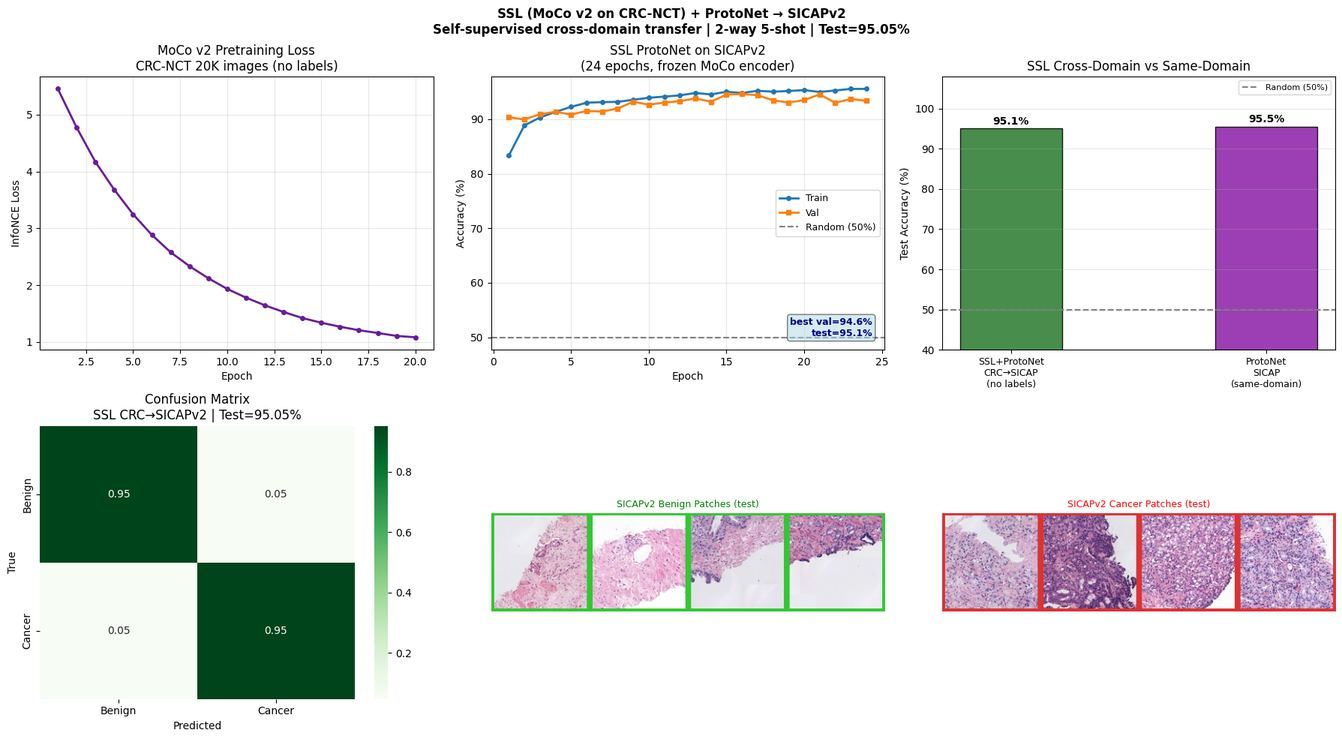

              precision    recall  f1-score   support

      Benign       0.95      0.95      0.95      1000
      Cancer       0.95      0.95      0.95      1000

    accuracy                           0.95      2000
   macro avg       0.95      0.95      0.95      2000
weighted avg       0.95      0.95      0.95      2000

Saved.


In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import (confusion_matrix,
                              classification_report)
from PIL import Image

fig = plt.figure(figsize=(18, 10))
actual_epochs = len(history['train_acc'])
ep = range(1, actual_epochs + 1)

ax1 = fig.add_subplot(2, 3, 1)
ax1.plot(range(1, len(moco_losses)+1), moco_losses,
         'o-', color='#6A1B9A', markersize=4, linewidth=2)
ax1.set_title('MoCo v2 Pretraining Loss\n'
              'CRC-NCT 20K images (no labels)')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('InfoNCE Loss')
ax1.grid(alpha=0.3)

#ProtoNet training curve
ax2 = fig.add_subplot(2, 3, 2)
ax2.plot(ep, history['train_acc'], 'o-',
         label='Train', markersize=4, linewidth=2)
ax2.plot(ep, history['val_acc'], 's-',
         label='Val', markersize=4, linewidth=2)
ax2.axhline(baseline, color='gray', linestyle='--',
            linewidth=1.5,
            label=f'Random ({baseline:.0f}%)')
ax2.set_title(f'SSL ProtoNet on SICAPv2\n'
              f'({actual_epochs} epochs, frozen MoCo encoder)')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy (%)')
ax2.legend(fontsize=9); ax2.grid(alpha=0.3)
best_v = max(history['val_acc'])
ax2.text(0.97, 0.05,
         f'best val={best_v:.1f}%\ntest={test_acc:.1f}%',
         transform=ax2.transAxes, ha='right',
         fontsize=9, color='navy', fontweight='bold',
         bbox=dict(boxstyle='round',
                   facecolor='lightblue', alpha=0.5))

#bar chart
ax3 = fig.add_subplot(2, 3, 3)
names = [
    'SSL+ProtoNet\nCRC→SICAP\n(no labels)',
    'ProtoNet\nSICAP\n(same-domain)',
]
accs   = [test_acc, 95.45]
colors = ['#2E7D32', '#8E24AA']
bars   = ax3.bar(range(2), accs, color=colors,
                 alpha=0.88, edgecolor='black', width=0.4)
ax3.axhline(baseline, color='gray', linestyle='--',
            linewidth=1.5,
            label=f'Random ({baseline:.0f}%)')
for bar, acc in zip(bars, accs):
    ax3.text(bar.get_x()+bar.get_width()/2,
             bar.get_height()+0.5,
             f'{acc:.1f}%', ha='center', va='bottom',
             fontweight='bold', fontsize=10)
ax3.set_xticks(range(2))
ax3.set_xticklabels(names, fontsize=9)
ax3.set_ylabel('Test Accuracy (%)')
ax3.set_title('SSL Cross-Domain vs Same-Domain')
ax3.set_ylim(40, 108)
ax3.legend(fontsize=8); ax3.grid(axis='y', alpha=0.3)

# Confusion matrix
ax4 = fig.add_subplot(2, 3, 4)
class_names = ['Benign', 'Cancer']
cm   = confusion_matrix(all_labels, all_preds)
cm_n = cm.astype(float) / cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_n, annot=True, fmt='.2f', cmap='Greens',
            xticklabels=class_names,
            yticklabels=class_names, ax=ax4)
ax4.set_title(f'Confusion Matrix\n'
              f'SSL CRC→SICAPv2 | Test={test_acc:.2f}%')
ax4.set_xlabel('Predicted')
ax4.set_ylabel('True')

#Sample images
random.seed(42)

def show_samples(ax, paths, title, border_color, n=4):
    sampled = random.sample(paths, min(n, len(paths)))
    strip   = []
    for p in sampled:
        img = np.array(
            Image.open(p).convert('RGB')
            .resize((128, 128)))
        bordered = np.ones((136, 136, 3), dtype=np.uint8)
        if border_color == 'green':
            bordered[:, :] = [50, 200, 50]
        else:
            bordered[:, :] = [220, 50, 50]
        bordered[4:132, 4:132] = img
        strip.append(bordered)
    combined = np.concatenate(strip, axis=1)
    ax.imshow(combined)
    ax.set_title(title, fontsize=9,
                 color='green' if border_color == 'green'
                 else 'red')
    ax.axis('off')

ax5 = fig.add_subplot(2, 3, 5)
show_samples(ax5, list(sic_test['benign']),
             'SICAPv2 Benign Patches (test)', 'green')

ax6 = fig.add_subplot(2, 3, 6)
show_samples(ax6, list(sic_test['cancer']),
             'SICAPv2 Cancer Patches (test)', 'red')

plt.suptitle(
    f'SSL (MoCo v2 on CRC-NCT) + ProtoNet → SICAPv2\n'
    f'Self-supervised cross-domain transfer | '
    f'{N_WAY}-way {K_SHOT}-shot | Test={test_acc:.2f}%',
    fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,
    'ssl_moco_protonet_results.png'), dpi=150)
plt.show()
print(classification_report(
    all_labels, all_preds, target_names=class_names))
print('Saved.')

In [12]:
import torch, os

CRC_ROOT   = '/kaggle/input/datasets/rayeneeeeeeeeee/nctcrche100k/9 Class Colon Cancer Histopathological Image'
SICAP_IMG  = '/kaggle/input/datasets/rayeneeeeeeeeee/sicapv2/SICAPv2_Kaggle/Train/Images'
SICAP_MSK  = '/kaggle/input/datasets/rayeneeeeeeeeee/sicapv2/SICAPv2_Kaggle/Train/Masks'
OUT_DIR    = '/kaggle/working'

# MoCo encoder checkpoint
MOCO_CKPT  = os.path.join(OUT_DIR, 'moco_v2_crc_encoder.pt')

# Verify checkpoint
assert os.path.exists(MOCO_CKPT), (
    f'MoCo checkpoint not found: {MOCO_CKPT}\n'
    f'Run NB4 first to generate it.')
print(f'MoCo checkpoint found: {MOCO_CKPT}')

N_WAY     = 2
K_SHOT    = 5
Q_QUERY   = 10
META_BS   = 4
PROTO_LR  = 0.0001
NUM_EPOCHS = 30
TRAIN_EPS  = 400
VAL_EPS    = 100
TEST_EPS   = 100

IMG_SIZE = 128
DEVICE   = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f'Device  : {DEVICE}')
print(f'FSL     : {N_WAY}-way {K_SHOT}-shot')
print(f'Encoder : MoCo v2 pretrained on CRC-NCT')
print(f'Exp-A   : Train CRC-NCT 9-class → Test SICAPv2')
print(f'Exp-B   : Train SICAPv2 → Test CRC-NCT binary')

MoCo checkpoint found: /kaggle/working/moco_v2_crc_encoder.pt
Device  : cuda
FSL     : 2-way 5-shot
Encoder : MoCo v2 pretrained on CRC-NCT
Exp-A   : Train CRC-NCT 9-class → Test SICAPv2
Exp-B   : Train SICAPv2 → Test CRC-NCT binary


In [13]:
import os, random
import numpy as np
from PIL import Image

random.seed(42)

def get_sicap_binary(img_dir, mask_dir,
                     cancer_thresh=0.30,
                     max_benign=2000, seed=42):
    random.seed(seed)
    cancer, benign = [], []
    for fname in sorted(os.listdir(img_dir)):
        mpath = os.path.join(mask_dir, fname)
        ipath = os.path.join(img_dir,  fname)
        if not os.path.exists(mpath): continue
        mask  = np.array(Image.open(mpath))
        c_pct = (mask == 100).sum() / mask.size
        b_pct = (mask == 0).sum()   / mask.size
        if c_pct > cancer_thresh:
            cancer.append(ipath)
        elif b_pct > 0.5 and c_pct < 0.10:
            benign.append(ipath)
    random.shuffle(benign)
    benign = benign[:max_benign]
    print(f'SICAPv2: {len(cancer)} cancer, {len(benign)} benign')
    return {'benign': benign, 'cancer': cancer}


def get_crc_multiclass(crc_root):
    classes = sorted([
        d for d in os.listdir(crc_root)
        if os.path.isdir(os.path.join(crc_root, d))])
    class_to_files = {}
    for c in classes:
        folder = os.path.join(crc_root, c)
        files  = [
            os.path.join(folder, f)
            for f in os.listdir(folder)
            if f.lower().endswith(
                ('.jpg','.jpeg','.png','.tif'))]
        class_to_files[c] = files
        print(f'  {c:45s}: {len(files):6,}')
    print(f'Total: {sum(len(v) for v in class_to_files.values()):,}')
    return class_to_files

def get_crc_binary(crc_root, seed=42):
    random.seed(seed)
    cancer_p, benign_p = [], []
    for cls in os.listdir(crc_root):
        cls_path = os.path.join(crc_root, cls)
        if not os.path.isdir(cls_path): continue
        for fname in os.listdir(cls_path):
            if fname.lower().endswith(
                    ('.jpg','.jpeg','.png','.tif')):
                fpath = os.path.join(cls_path, fname)
                if 'tumor' in cls.lower():
                    cancer_p.append(fpath)
                else:
                    benign_p.append(fpath)
    random.shuffle(benign_p)
    benign_p = benign_p[:len(cancer_p)]
    print(f'CRC binary: {len(cancer_p)} cancer, '
          f'{len(benign_p)} benign')
    return {'benign': benign_p, 'cancer': cancer_p}

def make_img_dict(class_to_files, fs, fe):
    d = {}
    for c, files in class_to_files.items():
        f = files[:]
        random.shuffle(f)
        d[c] = f[int(fs*len(f)) : int(fe*len(f))]
    return d

print('Loading CRC-NCT 9-class...')
crc_multiclass = get_crc_multiclass(CRC_ROOT)

print('\nLoading CRC-NCT binary...')
crc_binary = get_crc_binary(CRC_ROOT)

print('\nLoading SICAPv2...')
sicap_data = get_sicap_binary(SICAP_IMG, SICAP_MSK)

crc_train = make_img_dict(crc_multiclass, 0.00, 0.70)
crc_val   = make_img_dict(crc_multiclass, 0.70, 0.85)

crc_bin_train = make_img_dict(crc_binary, 0.00, 0.70)
crc_bin_val   = make_img_dict(crc_binary, 0.70, 0.85)
crc_bin_test  = make_img_dict(crc_binary, 0.85, 1.00)

sic_train = make_img_dict(sicap_data, 0.00, 0.70)
sic_val   = make_img_dict(sicap_data, 0.70, 0.85)
sic_test  = make_img_dict(sicap_data, 0.85, 1.00)

print('\nSplits:')
for name, d in [('CRC train', crc_train),
                ('CRC val',   crc_val),
                ('SICAP test', sic_test),
                ('CRC bin test', crc_bin_test)]:
    total = sum(len(v) for v in d.values())
    print(f'  {name:15s}: {len(d)} classes, {total:,} images')

Loading CRC-NCT 9-class...
  1. Normal                                    :  8,763
  2. Tumor                                     : 14,317
  3. Stroma                                    : 10,446
  4. Lympho                                    : 11,557
  5. Complex                                   : 13,536
  6. Debris                                    : 11,512
  7. Mucosa                                    :  8,896
  8. Adipose                                   : 10,407
  9. Background                                : 10,566
Total: 100,000

Loading CRC-NCT binary...
CRC binary: 14317 cancer, 14317 benign

Loading SICAPv2...
SICAPv2: 1293 cancer, 2000 benign

Splits:
  CRC train      : 9 classes, 69,996 images
  CRC val        : 9 classes, 15,000 images
  SICAP test     : 2 classes, 494 images
  CRC bin test   : 2 classes, 4,296 images


In [ ]:
import time, gc
import torch.nn as nn
from torch.utils.data import DataLoader


def run_experiment(name, train_dict, val_dict, test_dict,
                   ckpt_name, train_n_way=N_WAY,
                   num_epochs=NUM_EPOCHS, patience=8):
    """Train the projection head on `train_dict` episodes (frozen MoCo
    encoder), early-stop on `val_dict`, then test on `test_dict`.
    Returns (test_acc, history, model, preds, labels)."""
    print(f'\n{"="*60}')
    print(f'  {name}')
    print(f'{"="*60}')
    print(f'Train: {train_n_way}-way | Val: {N_WAY}-way | '
          f'Test: {N_WAY}-way\n')

    print('Train:')
    tr_ds = FSLDataset(train_dict, train_n_way, K_SHOT, Q_QUERY,
                       TRAIN_EPS, IMG_SIZE, augment=True)
    print('Val:')
    vl_ds = FSLDataset(val_dict, N_WAY, K_SHOT, Q_QUERY,
                       VAL_EPS, IMG_SIZE)
    print('Test (cross-domain):')
    te_ds = FSLDataset(test_dict, N_WAY, K_SHOT, Q_QUERY,
                       TEST_EPS, IMG_SIZE)

    tr_dl = DataLoader(tr_ds, META_BS, shuffle=True,
                       num_workers=2, collate_fn=collate_episodes)
    vl_dl = DataLoader(vl_ds, META_BS, shuffle=False,
                       num_workers=2, collate_fn=collate_episodes)
    te_dl = DataLoader(te_ds, META_BS, shuffle=False,
                       num_workers=2, collate_fn=collate_episodes)

    model = SSLPEncoder(MOCO_CKPT, proj_dim=128).to(DEVICE)
    ckpt  = os.path.join(OUT_DIR, ckpt_name)

    optimizer = torch.optim.Adam(
        model.proj.parameters(),
        lr=PROTO_LR, weight_decay=1e-3)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer, T_max=num_epochs, eta_min=1e-8)

    best_val, no_imp = 0.0, 0
    hist = {'train_acc': [], 'val_acc': [],
            'train_loss': [], 'val_loss': []}

    print(f'\nTraining {num_epochs} epochs (patience={patience})...')
    print('-' * 60)

    for epoch in range(1, num_epochs + 1):
        model.train()
        ep_accs, ep_losses = [], []
        t0 = time.time()

        for batch in tr_dl:
            optimizer.zero_grad(set_to_none=True)
            batch_loss = torch.tensor(0.0, device=DEVICE)
            batch_accs = []
            for (sup, qry, s_tgt, q_tgt) in batch:
                sup   = sup.to(DEVICE); qry = qry.to(DEVICE)
                s_tgt = s_tgt.to(DEVICE); q_tgt = q_tgt.to(DEVICE)
                loss, acc = proto_episode(
                    model, sup, qry, s_tgt, q_tgt,
                    train_n_way, K_SHOT)
                batch_loss = batch_loss + loss
                batch_accs.append(acc)
            batch_loss = batch_loss / len(batch)
            batch_loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            ep_losses.append(batch_loss.item())
            ep_accs.extend(batch_accs)

        model.eval()
        val_accs, val_losses = [], []
        for batch in vl_dl:
            for (sup, qry, s_tgt, q_tgt) in batch:
                sup   = sup.to(DEVICE); qry = qry.to(DEVICE)
                s_tgt = s_tgt.to(DEVICE); q_tgt = q_tgt.to(DEVICE)
                with torch.no_grad():
                    loss, acc = proto_episode(
                        model, sup, qry, s_tgt, q_tgt,
                        N_WAY, K_SHOT)
                val_accs.append(acc)
                val_losses.append(loss.item())

        scheduler.step()
        tr_acc  = sum(ep_accs)    / len(ep_accs)
        tr_loss = sum(ep_losses)  / len(ep_losses)
        vl_acc  = sum(val_accs)   / len(val_accs)
        vl_loss = sum(val_losses) / len(val_losses)
        hist['train_acc'].append(tr_acc)
        hist['val_acc'].append(vl_acc)
        hist['train_loss'].append(tr_loss)
        hist['val_loss'].append(vl_loss)

        print(f'Ep {epoch:02d}/{num_epochs}  '
              f'Train {tr_acc:5.2f}% loss={tr_loss:.4f}  '
              f'Val {vl_acc:5.2f}% loss={vl_loss:.4f}  '
              f'({time.time()-t0:.0f}s)')

        if vl_acc > best_val:
            best_val = vl_acc
            no_imp   = 0
            torch.save(model.state_dict(), ckpt)
            print(f'  -> Saved (best val={best_val:.2f}%)')
        else:
            no_imp += 1
            if no_imp >= patience:
                print(f'  Early stop at epoch {epoch}')
                break

        torch.cuda.empty_cache(); gc.collect()

    # ── test with the best checkpoint ────────────────────────────────────────
    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))
    model.eval()
    te_accs, te_losses, preds_all, labels_all = [], [], [], []
    for batch in te_dl:
        for (sup, qry, s_tgt, q_tgt) in batch:
            sup   = sup.to(DEVICE); qry = qry.to(DEVICE)
            s_tgt = s_tgt.to(DEVICE); q_tgt = q_tgt.to(DEVICE)
            with torch.no_grad():
                loss, acc = proto_episode(
                    model, sup, qry, s_tgt, q_tgt,
                    N_WAY, K_SHOT)
                prototypes = model(sup).view(
                    N_WAY, K_SHOT, -1).mean(1)
                preds = euclidean_dist(
                    model(qry), prototypes).argmin(1).cpu().numpy()
            te_accs.append(acc)
            te_losses.append(loss.item())
            preds_all.extend(preds)
            labels_all.extend(q_tgt.cpu().numpy())

    test_acc  = sum(te_accs)   / len(te_accs)
    test_loss = sum(te_losses) / len(te_losses)
    baseline  = 100.0 / N_WAY
    print(f'\n  Random baseline : {baseline:.1f}%')
    print(f'  Test accuracy   : {test_acc:.2f}%')
    print(f'  Test loss       : {test_loss:.4f}')
    print(f'  Gain over random: +{test_acc-baseline:.2f}%')
    return test_acc, hist, model, preds_all, labels_all

print('run_experiment defined')

In [18]:
import time, gc
print('STAGE 1: Train projection head on CRC-NCT...')
acc_stage1, hist_stage1, model_A, _, _ = run_experiment(
    'Stage1: CRC-NCT 9-class (source)',
    crc_train,
    crc_val,
    sic_test,
    ckpt_name='moco_proto_stage1_crc.pt',
    train_n_way=5)
 
print('\nSTAGE 2: Fine-tune on SICAPv2 target domain...')

model_A.load_state_dict(
    torch.load(os.path.join(OUT_DIR,
               'moco_proto_stage1_crc.pt'),
               map_location=DEVICE))

ft_optimizer = torch.optim.Adam(
    model_A.proj.parameters(),
    lr=PROTO_LR * 0.1,
    weight_decay=1e-3)
ft_scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    ft_optimizer, T_max=20, eta_min=1e-9)

FT_EPOCHS = 20
ft_ckpt   = os.path.join(OUT_DIR,
                          'moco_proto_cross_crc_to_sicap.pt')
best_val  = 0.0
no_imp    = 0
patience  = 8
ft_hist   = {'train_acc': [], 'val_acc': []}

print('Fine-tune Train:')
ft_tr_ds = FSLDataset(sic_train, N_WAY, K_SHOT,
                      Q_QUERY, TRAIN_EPS,
                      IMG_SIZE, augment=True)
print('Fine-tune Val:')
ft_vl_ds = FSLDataset(sic_val, N_WAY, K_SHOT,
                      Q_QUERY, VAL_EPS, IMG_SIZE)
print('Test:')
ft_te_ds = FSLDataset(sic_test, N_WAY, K_SHOT,
                      Q_QUERY, TEST_EPS, IMG_SIZE)

ft_tr_dl = DataLoader(ft_tr_ds, META_BS, shuffle=True,
                      num_workers=2,
                      collate_fn=collate_episodes)
ft_vl_dl = DataLoader(ft_vl_ds, META_BS, shuffle=False,
                      num_workers=2,
                      collate_fn=collate_episodes)
ft_te_dl = DataLoader(ft_te_ds, META_BS, shuffle=False,
                      num_workers=2,
                      collate_fn=collate_episodes)

print(f'\nFine-tuning {FT_EPOCHS} epochs on SICAPv2...')
print('-' * 60)

for epoch in range(1, FT_EPOCHS + 1):
    model_A.train()
    ep_accs, ep_losses = [], []
    t0 = time.time()

    for batch in ft_tr_dl:
        ft_optimizer.zero_grad(set_to_none=True)
        batch_loss = torch.tensor(0.0, device=DEVICE)
        batch_accs = []
        for (sup, qry, s_tgt, q_tgt) in batch:
            sup   = sup.to(DEVICE)
            qry   = qry.to(DEVICE)
            s_tgt = s_tgt.to(DEVICE)
            q_tgt = q_tgt.to(DEVICE)
            loss, acc = proto_episode(
                model_A, sup, qry, s_tgt, q_tgt,
                N_WAY, K_SHOT)
            batch_loss = batch_loss + loss
            batch_accs.append(acc)
        batch_loss = batch_loss / len(batch)
        batch_loss.backward()
        nn.utils.clip_grad_norm_(
            model_A.parameters(), 5.0)
        ft_optimizer.step()
        ep_losses.append(batch_loss.item())
        ep_accs.extend(batch_accs)

    model_A.eval()
    val_accs = []
    for batch in ft_vl_dl:
        for (sup, qry, s_tgt, q_tgt) in batch:
            sup   = sup.to(DEVICE)
            qry   = qry.to(DEVICE)
            s_tgt = s_tgt.to(DEVICE)
            q_tgt = q_tgt.to(DEVICE)
            with torch.no_grad():
                _, acc = proto_episode(
                    model_A, sup, qry, s_tgt, q_tgt,
                    N_WAY, K_SHOT)
            val_accs.append(acc)

    ft_scheduler.step()
    tr_acc = sum(ep_accs)  / len(ep_accs)
    vl_acc = sum(val_accs) / len(val_accs)
    ft_hist['train_acc'].append(tr_acc)
    ft_hist['val_acc'].append(vl_acc)

    print(f'FT Ep {epoch:02d}/{FT_EPOCHS}  '
          f'Train {tr_acc:5.2f}%  '
          f'Val {vl_acc:5.2f}%  '
          f'({time.time()-t0:.0f}s)')

    if vl_acc > best_val:
        best_val = vl_acc
        no_imp   = 0
        torch.save(model_A.state_dict(), ft_ckpt)
        print(f'  -> Saved (best val={best_val:.2f}%)')
    else:
        no_imp += 1
        if no_imp >= patience:
            print(f'  Early stop at epoch {epoch}')
            break

    torch.cuda.empty_cache()
    gc.collect()

#test 
model_A.load_state_dict(
    torch.load(ft_ckpt, map_location=DEVICE))
model_A.eval()
te_accs, all_preds, all_labels = [], [], []

for batch in ft_te_dl:
    for (sup, qry, s_tgt, q_tgt) in batch:
        sup   = sup.to(DEVICE)
        qry   = qry.to(DEVICE)
        s_tgt = s_tgt.to(DEVICE)
        q_tgt = q_tgt.to(DEVICE)
        with torch.no_grad():
            _, acc = proto_episode(
                model_A, sup, qry, s_tgt, q_tgt,
                N_WAY, K_SHOT)
            sup_emb    = model_A(sup)
            prototypes = sup_emb.view(
                N_WAY, K_SHOT, -1).mean(1)
            preds      = euclidean_dist(
                model_A(qry),
                prototypes).argmin(1).cpu().numpy()
        te_accs.append(acc)
        all_preds.extend(preds)
        all_labels.extend(q_tgt.cpu().numpy())

acc_A   = sum(te_accs) / len(te_accs)
preds_A = all_preds
lbls_A  = all_labels
hist_A  = ft_hist

print(f'\n{"="*50}')
print(f'Exp-A: CRC-NCT → SICAPv2 (2-stage)')
print(f'{"="*50}')
print(f'Test accuracy   : {acc_A:.2f}%')
print(f'Gain over random: +{acc_A-50:.2f}%')

STAGE 1: Train projection head on CRC-NCT...

  Stage1: CRC-NCT 9-class (source)
Train: 5-way | Val: 2-way | Test: 2-way

Train:
Val:
Test (cross-domain):
MoCo encoder loaded and frozen
Projection head params: 181,504

Training 30 epochs (patience=8)...
------------------------------------------------------------
Ep 01/30  Train 81.79% loss=0.9767  Val 96.50% loss=0.2261  (201s)
  -> Saved (best val=96.50%)
Ep 02/30  Train 88.51% loss=0.6800  Val 98.05% loss=0.1818  (173s)
  -> Saved (best val=98.05%)
Ep 03/30  Train 90.46% loss=0.6267  Val 97.95% loss=0.1945  (158s)
Ep 04/30  Train 91.25% loss=0.6034  Val 99.00% loss=0.1510  (149s)
  -> Saved (best val=99.00%)
Ep 05/30  Train 92.40% loss=0.5768  Val 99.15% loss=0.1456  (145s)
  -> Saved (best val=99.15%)
Ep 06/30  Train 92.47% loss=0.5717  Val 98.15% loss=0.1731  (145s)
Ep 07/30  Train 93.61% loss=0.5559  Val 98.30% loss=0.1647  (145s)
Ep 08/30  Train 93.97% loss=0.5424  Val 99.30% loss=0.1495  (143s)
  -> Saved (best val=99.30%)
Ep 0


  Cross-Domain ProtoNet v2 — Exp-A Results
  2-way 5-shot | MoCo encoder 2-stage
  CRC-NCT → SICAPv2 : 89.35%  (+39.35%)
  vs same-domain    : 95.45%  (drop=6.10%)


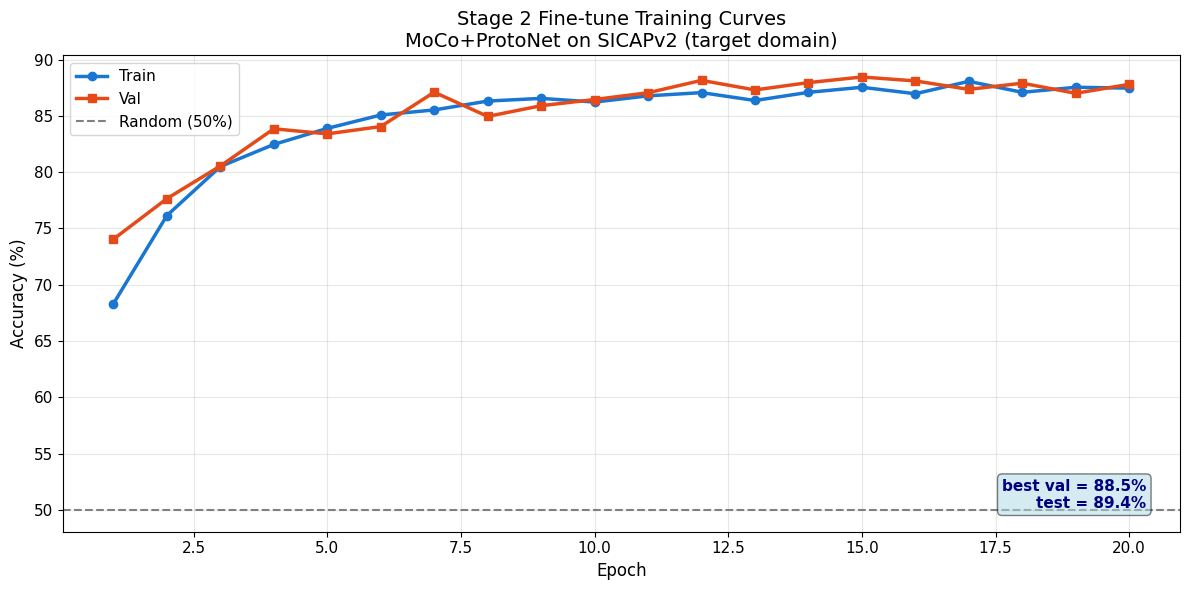

Training curves saved.


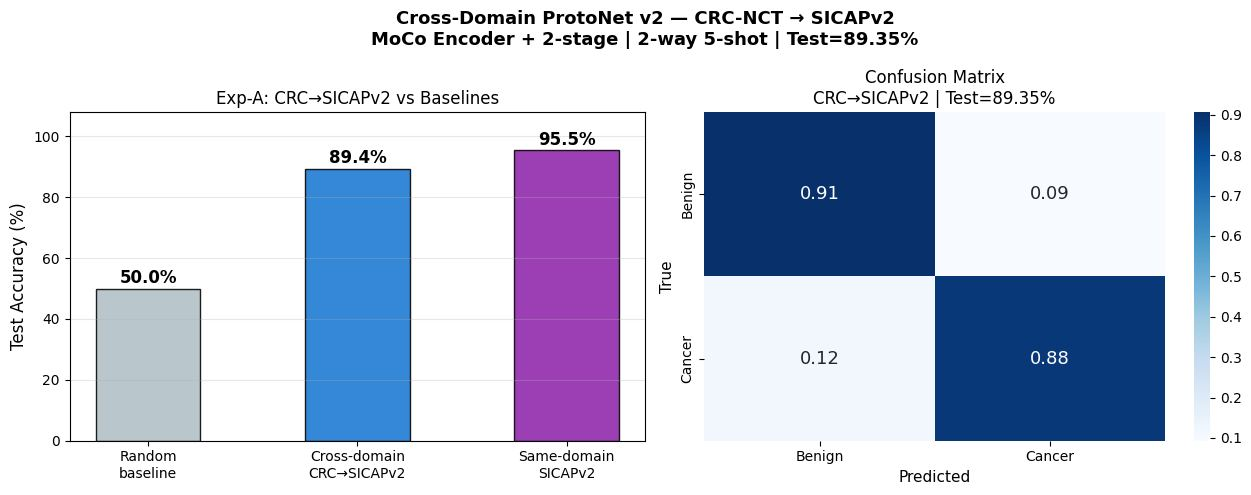

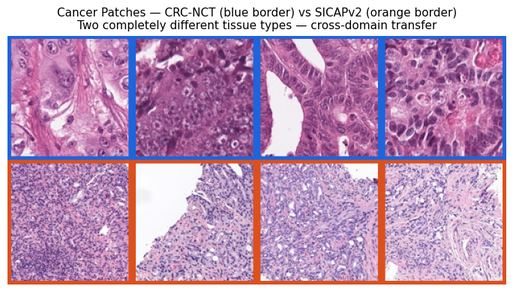

Patches saved.

Exp-A classification report:
              precision    recall  f1-score   support

      Benign       0.88      0.91      0.89      1000
      Cancer       0.90      0.88      0.89      1000

    accuracy                           0.89      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.89      0.89      0.89      2000



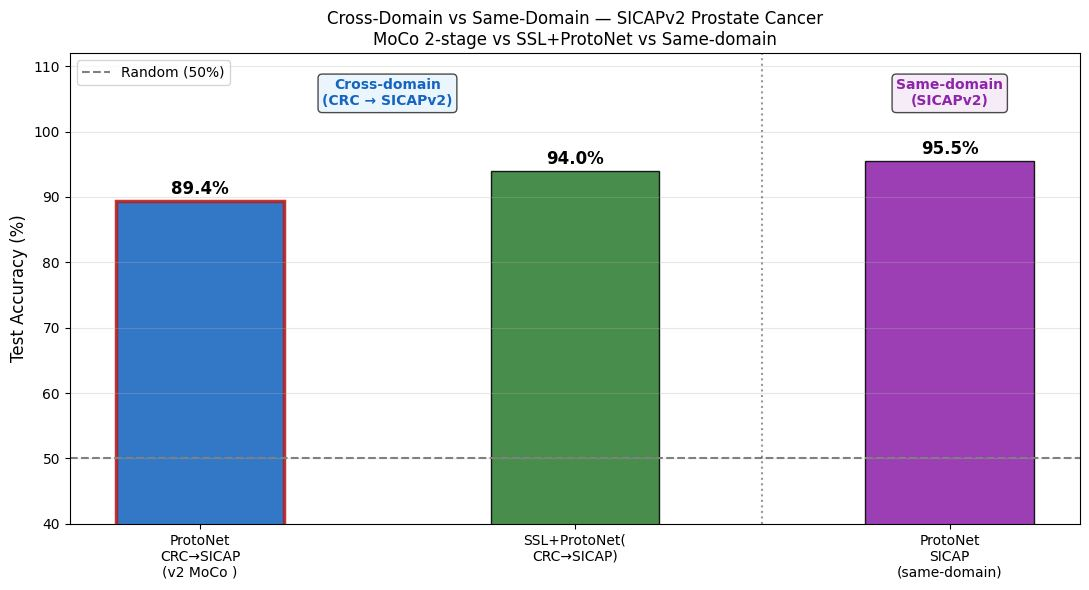

All plots saved.


In [22]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.metrics import (confusion_matrix,
                              classification_report)
from PIL import Image

baseline = 100.0 / N_WAY

print('\n' + '='*60)
print('  Cross-Domain ProtoNet v2 — Exp-A Results')
print(f'  {N_WAY}-way {K_SHOT}-shot | MoCo encoder 2-stage')
print('='*60)
print(f'  CRC-NCT → SICAPv2 : {acc_A:.2f}%  '
      f'(+{acc_A-baseline:.2f}%)')
print(f'  vs same-domain    : 95.45%  '
      f'(drop={95.45-acc_A:.2f}%)')
print('='*60)


fig1, ax1 = plt.subplots(figsize=(12, 6))
ep = range(1, len(hist_A['train_acc'])+1)
ax1.plot(ep, hist_A['train_acc'], 'o-',
         label='Train', color='#1976D2',
         markersize=6, linewidth=2.5)
ax1.plot(ep, hist_A['val_acc'], 's-',
         label='Val', color='#E64A19',
         markersize=6, linewidth=2.5)
ax1.axhline(baseline, color='gray', linestyle='--',
            linewidth=1.5, label=f'Random ({baseline:.0f}%)')
ax1.set_title('Stage 2 Fine-tune Training Curves\n'
              'MoCo+ProtoNet on SICAPv2 (target domain)',
              fontsize=14)
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Accuracy (%)', fontsize=12)
ax1.legend(fontsize=11)
ax1.grid(alpha=0.3)
ax1.tick_params(labelsize=11)
best_v = max(hist_A['val_acc'])
ax1.text(0.97, 0.05,
         f'best val = {best_v:.1f}%\ntest = {acc_A:.1f}%',
         transform=ax1.transAxes, ha='right',
         fontsize=11, color='navy', fontweight='bold',
         bbox=dict(boxstyle='round',
                   facecolor='lightblue', alpha=0.5))
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,
    'expa_training_curves.png'), dpi=150)
plt.show()
print('Training curves saved.')

fig2, (ax2, ax3) = plt.subplots(1, 2, figsize=(13, 5))

# Bar chart
names_bar = [
    'Random\nbaseline',
    'Cross-domain\nCRC→SICAPv2',
    'Same-domain\nSICAPv2',
]
accs_bar   = [50.0, acc_A, 95.45]
colors_bar = ['#B0BEC5', '#1976D2', '#8E24AA']
bars = ax2.bar(range(3), accs_bar, color=colors_bar,
               alpha=0.88, edgecolor='black', width=0.5)
for bar, acc in zip(bars, accs_bar):
    ax2.text(bar.get_x()+bar.get_width()/2,
             bar.get_height()+0.5,
             f'{acc:.1f}%', ha='center', va='bottom',
             fontweight='bold', fontsize=12)
ax2.set_xticks(range(3))
ax2.set_xticklabels(names_bar, fontsize=10)
ax2.set_ylabel('Test Accuracy (%)', fontsize=12)
ax2.set_title('Exp-A: CRC→SICAPv2 vs Baselines',
              fontsize=12)
ax2.set_ylim(0, 108)
ax2.grid(axis='y', alpha=0.3)

# Confusion matrix
class_names = ['Benign', 'Cancer']
cm   = confusion_matrix(lbls_A, preds_A)
cm_n = cm.astype(float)/cm.sum(axis=1, keepdims=True)
sns.heatmap(cm_n, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names, ax=ax3,
            annot_kws={'size': 13})
ax3.set_title(f'Confusion Matrix\n'
              f'CRC→SICAPv2 | Test={acc_A:.2f}%',
              fontsize=12)
ax3.set_xlabel('Predicted', fontsize=11)
ax3.set_ylabel('True', fontsize=11)

plt.suptitle(
    f'Cross-Domain ProtoNet v2 — CRC-NCT → SICAPv2\n'
    f'MoCo Encoder + 2-stage | '
    f'{N_WAY}-way {K_SHOT}-shot | Test={acc_A:.2f}%',
    fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,
    'expa_bar_confusion.png'), dpi=150)
plt.show()

random.seed(42)
fig3, ax4 = plt.subplots(figsize=(12, 4))

def make_strip(paths, border_color, n=4):
    sampled = random.sample(list(paths), min(n, len(paths)))
    strip   = []
    for p in sampled:
        img = np.array(
            Image.open(p).convert('RGB')
            .resize((128, 128)))
        bordered = np.ones((136, 136, 3), dtype=np.uint8)
        if border_color == 'blue':
            bordered[:, :] = [30, 100, 220]
        else:
            bordered[:, :] = [220, 80, 30]
        bordered[4:132, 4:132] = img
        strip.append(bordered)
    return np.concatenate(strip, axis=1)

crc_strip   = make_strip(crc_bin_test['cancer'], 'blue')
sicap_strip = make_strip(sic_test['cancer'], 'orange')
combined    = np.concatenate([crc_strip, sicap_strip], axis=0)
ax4.imshow(combined)
ax4.set_title(
    'Cancer Patches — CRC-NCT (blue border) vs SICAPv2 (orange border)\n'
    'Two completely different tissue types — cross-domain transfer',
    fontsize=11)
ax4.axis('off')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,
    'expa_cancer_patches.png'), dpi=150)
plt.show()
print('Patches saved.')

print('\nExp-A classification report:')
print(classification_report(
    lbls_A, preds_A, target_names=class_names))

fig4, ax5 = plt.subplots(figsize=(11, 6))

names_cmp = [
    'ProtoNet\nCRC→SICAP\n(v2 MoCo )',
    'SSL+ProtoNet(\nCRC→SICAP)',
    'ProtoNet\nSICAP\n(same-domain)',
]
accs_cmp   = [acc_A, 94.0, 95.45]
colors_cmp = ['#1565C0', '#2E7D32', '#8E24AA']

bars3 = ax5.bar(range(3), accs_cmp, color=colors_cmp,
                alpha=0.88, edgecolor='black', width=0.45)
ax5.axhline(50, color='gray', linestyle='--',
            linewidth=1.5, label='Random (50%)')

bars3[0].set_edgecolor('#B71C1C')
bars3[0].set_linewidth(2.5)

for bar, acc in zip(bars3, accs_cmp):
    ax5.text(bar.get_x()+bar.get_width()/2,
             bar.get_height()+0.5,
             f'{acc:.1f}%', ha='center', va='bottom',
             fontweight='bold', fontsize=12)

ax5.axvline(1.5, color='black', linestyle=':',
            alpha=0.4, linewidth=1.5)

ax5.text(0.5, 104, 'Cross-domain\n(CRC → SICAPv2)',
         ha='center', fontsize=10, color='#1565C0',
         fontweight='bold',
         bbox=dict(boxstyle='round',
                   facecolor='#E3F2FD', alpha=0.7))
ax5.text(2.0, 104, 'Same-domain\n(SICAPv2)',
         ha='center', fontsize=10, color='#8E24AA',
         fontweight='bold',
         bbox=dict(boxstyle='round',
                   facecolor='#F3E5F5', alpha=0.7))

ax5.set_xticks(range(3))
ax5.set_xticklabels(names_cmp, fontsize=10)
ax5.set_ylabel('Test Accuracy (%)', fontsize=12)
ax5.set_title(
    'Cross-Domain vs Same-Domain — SICAPv2 Prostate Cancer\n'
    'MoCo 2-stage vs SSL+ProtoNet vs Same-domain',
    fontsize=12)
ax5.set_ylim(40, 112)
ax5.legend(fontsize=10)
ax5.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR,
    'crossdomain_comparison_final.png'), dpi=150)
plt.show()
print('All plots saved.')